# ZeRO 1 / 2 / 3 on 32 Virtual GPUs

**What this notebook does.** It builds 32 virtual GPUs, trains one small MLP across them four times —
once with plain data parallelism and once for each ZeRO stage — and **measures** what changes:
memory resident per GPU, peak memory, bytes on the wire, and FLOPs.

**The claim being tested.** ZeRO removes memory redundancy from data parallelism without changing the
arithmetic. If the implementation is honest, all four runs must produce *the same loss curve* while the
memory per GPU falls by up to 32x. The notebook asserts exactly that.

| | Baseline DP | ZeRO-1 | ZeRO-2 | ZeRO-3 |
|---|---|---|---|---|
| fp16 parameters | replicated | replicated | replicated | **sharded** |
| fp16 gradients | replicated | replicated | **sharded** | **sharded** |
| fp32 optimizer states | replicated | **sharded** | **sharded** | **sharded** |
| memory / GPU | `16Ψ` | `4Ψ + 12Ψ/N` | `2Ψ + 14Ψ/N` | `16Ψ/N` |
| comm / step | `2Ψ` | `2Ψ` | `2Ψ` | `3Ψ` |
| matmul FLOPs / GPU | `F` | `F` | `F` | `F` |
| optimizer updates / GPU | `Ψ` | `Ψ/N` | `Ψ/N` | `Ψ/N` |

`Ψ` = parameter count, `N` = number of GPUs. Run everything top to bottom; it takes about a minute.

## 1. Why `16Ψ`?

Mixed-precision Adam keeps six things alive for every parameter:

| tensor | dtype | bytes / param |
|---|---|---|
| parameters (compute copy) | fp16 | 2 |
| gradients | fp16 | 2 |
| parameters (fp32 master copy) | fp32 | 4 |
| Adam momentum `m` | fp32 | 4 |
| Adam variance `v` | fp32 | 4 |
| | | **16** |

The last three — 12 bytes per parameter, `K=12` in the ZeRO paper — exist only for the optimizer
*update*, which is elementwise. Nothing about Adam requires rank 7 to own the momentum for a parameter
that rank 7 is not updating. That is the redundancy ZeRO deletes, one tier at a time:

- **ZeRO-1** (`P_os`) shards the 12 fp32 bytes. Each rank updates only its slice, then all-gathers the
  refreshed fp16 parameters.
- **ZeRO-2** (`P_os+g`) also shards the gradients. Each layer's gradient is reduce-scattered the moment
  backward produces it; every rank keeps only its own slice and frees the rest.
- **ZeRO-3** (`P_os+g+p`) also shards the parameters. A layer's weights are all-gathered right before
  they are used and freed right after, in both forward and backward — which is where the extra `Ψ` of
  communication comes from.

## 2. Setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIGDIR = Path('figures'); FIGDIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'savefig.facecolor': 'white',
                     'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

N_GPUS   = 32                                    # 32 virtual GPUs
LAYERS   = [(256, 512), (512, 512), (512, 10)]   # MLP, (in, out) per layer
GLOBAL_BATCH = 1024                              # -> 32 samples per GPU
STEPS    = 25
LR, B1, B2, EPS = 3e-3, 0.9, 0.999, 1e-8
WIRE     = 2                                     # gradients/params cross the wire as fp16
FP16, FP32 = np.float16, np.float32
D_IN, N_CLASS = LAYERS[0][0], LAYERS[-1][1]

STAGE_NAMES = {0: 'Baseline DP', 1: 'ZeRO-1 (Pos)', 2: 'ZeRO-2 (Pos+g)', 3: 'ZeRO-3 (Pos+g+p)'}
COLORS      = {0: '#8c8c8c', 1: '#4c78a8', 2: '#f58518', 3: '#54a24b'}
MB = 2 ** 20
print(f'{N_GPUS} virtual GPUs | MLP {LAYERS} | global batch {GLOBAL_BATCH}'
      f' -> {GLOBAL_BATCH // N_GPUS} samples/GPU')

32 virtual GPUs | MLP [(256, 512), (512, 512), (512, 10)] | global batch 1024 -> 32 samples/GPU


### A note on "virtual GPU"

Each virtual GPU is a `VGPU` object that owns its own numpy arrays. The 32 of them execute
**sequentially** inside one Python process, bulk-synchronous: every rank finishes layer *i* before any
rank starts layer *i+1*, which is exactly where a real collective would sit.

What is real here: the sharding (each rank physically allocates only its slice), the collectives (data
genuinely moves between the 32 separate arrays), the byte counts, and the arithmetic. What is not real:
wall-clock parallelism. Python threads would not fix that — the GIL serialises them anyway — and a
wall-clock number from 32 GIL-bound threads would be a worse lie than not reporting one. So this
notebook reports **FLOPs and communicated bytes**, which are the quantities a distributed run is
actually bounded by, and never reports a speedup.

## 3. One flat parameter vector

Real ZeRO implementations flatten every parameter into one contiguous buffer and shard *that*, rather
than assigning whole tensors to ranks — it keeps shards exactly equal in size. We do the same: `Ψ`
elements, padded up to a multiple of `N`, and rank `r` owns `[r·S, (r+1)·S)`.

Shard boundaries therefore cut *through* layers, which is fine and is what DeepSpeed does. Each layer
still gets one contiguous **bucket** `[lo, hi)` in the flat vector, and that bucket is the unit that
gets all-gathered and reduce-scattered.

In [2]:
def layout(layers):
    """Map each layer's W and b onto one flat vector."""
    spec, off = [], 0
    for nin, nout in layers:
        spec.append(dict(w=(off, off + nin * nout), shape=(nin, nout),
                         b=(off + nin * nout, off + nin * nout + nout)))
        off += nin * nout + nout
    return spec, off

SPEC, PSI = layout(LAYERS)
SHARD   = -(-PSI // N_GPUS)                        # ceil -> equal shards
PSI_PAD = SHARD * N_GPUS
NL      = len(SPEC)
BUCKET  = [(s['w'][0], s['b'][1]) for s in SPEC]    # contiguous range per layer

print(f'psi = {PSI:,} params -> padded {PSI_PAD:,} -> shard {SHARD:,} elements/GPU')
for i, (lo, hi) in enumerate(BUCKET):
    print(f'  layer {i}: {LAYERS[i][0]:>4} x {LAYERS[i][1]:<4}  flat[{lo:,}:{hi:,}]  '
          f'{(hi-lo)/PSI:5.1%} of the model')

psi = 399,370 params -> padded 399,392 -> shard 12,481 elements/GPU
  layer 0:  256 x 512   flat[0:131,584]  32.9% of the model
  layer 1:  512 x 512   flat[131,584:394,240]  65.8% of the model
  layer 2:  512 x 10    flat[394,240:399,370]   1.3% of the model


## 4. Collectives, with a byte meter

Three collectives are enough for all four configurations.

| collective | what it does | bytes moved *per rank* |
|---|---|---|
| `all_reduce(x)` | every rank ends with the mean of all ranks' `x` | `2 x (N-1)/N x size(x)` |
| `reduce_scatter(x)` | rank `r` ends with the mean, restricted to its own shard | `(N-1)/N x size(x)` |
| `all_gather(shards)` | every rank ends with the concatenation | `(N-1)/N x size(out)` |

Those are ring-algorithm volumes. The `(N-1)/N` factor is why the measurements below land at `1.94x`
and `2.91x` rather than exactly `2x` and `3x` — at `N=32`, `31/32 = 0.969`.

Reductions accumulate in fp32 and round to fp16 at the end, in a fixed rank order, for every stage.
That is what makes the four runs bitwise comparable later.

In [3]:
class Comm:
    """Collectives over the 32 virtual GPUs, metering bytes that cross the wire per rank."""

    def __init__(self, n):
        self.n, self.bytes, self.ops = n, 0.0, {}

    def _charge(self, elems, factor, op):
        self.bytes += factor * (self.n - 1) / self.n * elems * WIRE
        self.ops[op] = self.ops.get(op, 0) + 1

    def all_reduce(self, contribs):
        acc = np.zeros(contribs[0].shape, FP32)
        for c in contribs:                      # fixed rank order -> reproducible
            acc += c
        acc /= self.n
        self._charge(acc.size, 2, 'all_reduce')
        return acc.astype(FP16)

    def reduce_scatter(self, contribs, lo, hi, shard):
        """contribs[r] = rank r's local gradient for flat range [lo,hi). Rank r keeps its own slice."""
        acc = np.zeros(hi - lo, FP32)
        for c in contribs:
            acc += c
        acc /= self.n
        self._charge(hi - lo, 1, 'reduce_scatter')
        out = []
        for r in range(self.n):
            a, b = r * shard, (r + 1) * shard
            i0, i1 = max(lo, a), min(hi, b)     # this shard may not touch this bucket at all
            out.append((i0 - a, acc[i0 - lo:i1 - lo].astype(FP16)) if i1 > i0 else (0, None))
        return out

    def all_gather(self, parts):
        out = np.concatenate(parts)
        self._charge(out.size, 1, 'all_gather')
        return out

## 5. The virtual GPU

This is where the whole simulation lives or dies: a `VGPU` allocates **only what its stage permits**.
Nothing is hidden behind a formula — `state_bytes()` sums `.nbytes` of the arrays that actually exist,
so the memory results later are measurements of real allocations, not the table from section 1
restated.

```
stage 0   p16: Ψ      g16: Ψ      master/m/v: Ψ each     = 16Ψ
stage 1   p16: Ψ      g16: Ψ      master/m/v: Ψ/N each   = 4Ψ + 12Ψ/N
stage 2   p16: Ψ      g16: Ψ/N    master/m/v: Ψ/N each   = 2Ψ + 14Ψ/N
stage 3   p16: Ψ/N    g16: Ψ/N    master/m/v: Ψ/N each   = 16Ψ/N
```

In [4]:
class VGPU:
    """One virtual GPU. Allocates only what its ZeRO stage allows it to hold."""

    def __init__(self, rank, stage, master0, shard=None, psi_pad=None):
        shard   = SHARD if shard is None else shard
        psi_pad = PSI_PAD if psi_pad is None else psi_pad
        self.rank, self.stage = rank, stage
        self.lo, self.hi = rank * shard, (rank + 1) * shard
        me = slice(self.lo, self.hi)

        self.p16    = (master0 if stage < 3 else master0[me]).astype(FP16)   # stage 3 shards params
        self.g16    = np.zeros(psi_pad if stage < 2 else shard, FP16)        # stage 2+ shards grads
        self.master = (master0 if stage == 0 else master0[me]).astype(FP32)  # stage 1+ shards fp32
        n_opt       = psi_pad if stage == 0 else shard
        self.m      = np.zeros(n_opt, FP32)
        self.v      = np.zeros(n_opt, FP32)
        self.flops, self.peak, self.opt_elems = 0, 0, 0

    def state_bytes(self):
        """Persistent model-state bytes actually resident on this GPU. Measured, not derived."""
        return dict(params=self.p16.nbytes, grads=self.g16.nbytes,
                    optimizer=self.master.nbytes + self.m.nbytes + self.v.nbytes)

    def note_peak(self, transient):
        """Peak = persistent state + whatever transient buffers are live right now."""
        self.peak = max(self.peak, sum(self.state_bytes().values()) + transient)

    def adam(self, g, t):
        """Adam is fully elementwise -> updating a shard gives the same answer as updating the whole."""
        self.m = B1 * self.m + (1 - B1) * g
        self.v = B2 * self.v + (1 - B2) * g * g
        mh = self.m / (1 - B1 ** t)
        vh = self.v / (1 - B2 ** t)
        self.master -= LR * mh / (np.sqrt(vh) + EPS)
        self.opt_elems += g.size                   # optimizer work done by this GPU

> **Why sharding Adam is exactly equivalent.** Every line of `adam()` is elementwise. Parameter `j`'s
> update reads only `g[j]`, `m[j]`, `v[j]`, `master[j]`. So splitting the vector across 32 ranks and
> having each update its own slice produces the *identical* result, not an approximation. This is the
> entire reason ZeRO-1 is free. The assertion in section 8 is what turns that argument into evidence.

## 6. One training step

The step is bulk-synchronous over layers. Two helpers carry all the stage-specific behaviour:

- **`layer_params(i)`** — how a rank gets layer `i`'s weights. Stages 0–2 already hold them. Stage 3
  must **all-gather** the bucket from all 32 shards, use it, and drop it. That happens in forward *and*
  again in backward: `2Ψ` of gathering per step.
- **`deposit_grad(i)`** — what a rank does with the gradient it just produced. Stages 0–1 store the
  whole thing. Stages 2–3 **reduce-scatter** the bucket immediately and keep only their own slice,
  which is what makes gradient memory `Ψ/N` instead of `Ψ`.

In [5]:
def act_bytes(acts):
    return sum(a.size for a in acts[1:]) * 2       # fp16 activations stashed for backward

def layer_params(gpus, comm, stage, i):
    """(W, b) for every rank. Stage 3 all-gathers this layer's bucket, then frees it."""
    lo, hi = BUCKET[i]
    w0, w1 = SPEC[i]['w']
    shp    = SPEC[i]['shape']
    if stage < 3:                                  # params are resident: no communication
        flat, gathered = [g.p16[lo:hi].astype(FP32) for g in gpus], 0
    else:
        parts = []
        for g in gpus:
            i0, i1 = max(lo, g.lo), min(hi, g.hi)
            parts.append(g.p16[i0 - g.lo:i1 - g.lo] if i1 > i0 else g.p16[:0])
        full     = comm.all_gather(parts)          # transient: lives only for this layer
        flat     = [full.astype(FP32)] * len(gpus)
        gathered = full.nbytes
    return [(f[:w1 - w0].reshape(shp), f[w1 - w0:]) for f in flat], gathered

def deposit_grad(gpus, comm, stage, i, bucket):
    """Stages 0-1 keep the full gradient. Stages 2-3 reduce-scatter it now and free the rest."""
    lo, hi = BUCKET[i]
    if stage < 2:
        for g, c in zip(gpus, bucket):
            g.g16[lo:hi] = c
    else:
        for g, (off, val) in zip(gpus, comm.reduce_scatter(bucket, lo, hi, SHARD)):
            if val is not None:
                g.g16[off:off + val.size] = val

In [6]:
def train_step(gpus, comm, stage, xb, yb, t):
    """One optimizer step across all virtual GPUs. Returns the global mean loss."""
    n = len(gpus)
    xs, ys = np.split(xb, n), np.split(yb, n)      # data parallel: each rank gets its own micro-batch
    mb = xs[0].shape[0]
    acts = [[x] for x in xs]

    # ---------------- forward ----------------
    for i in range(NL):
        P, gathered = layer_params(gpus, comm, stage, i)
        nin, nout = SPEC[i]['shape']
        for r, g in enumerate(gpus):
            W, b = P[r]
            h = acts[r][-1] @ W + b
            acts[r].append(np.maximum(h, 0) if i < NL - 1 else h)
            g.flops += 2 * mb * nin * nout
            g.note_peak(gathered + act_bytes(acts[r]))
                                                   # stage 3: `gathered` is dropped here

    # ---------------- loss (softmax cross-entropy) ----------------
    d, loss = [], 0.0
    for r in range(n):
        z  = acts[r][-1]
        e  = np.exp(z - z.max(1, keepdims=True))
        sm = e / e.sum(1, keepdims=True)
        loss += -np.log(sm[np.arange(mb), ys[r]] + 1e-12).mean() / n
        dz = sm.copy()
        dz[np.arange(mb), ys[r]] -= 1
        d.append(dz / mb)

    # ---------------- backward ----------------
    for i in reversed(range(NL)):
        P, gathered = layer_params(gpus, comm, stage, i)   # stage 3 gathers a second time
        nin, nout = SPEC[i]['shape']
        bucket = []
        for r, g in enumerate(gpus):
            W, _ = P[r]
            gW = acts[r][i].T @ d[r]
            gb = d[r].sum(0)
            bucket.append(np.concatenate([gW.ravel(), gb]).astype(FP16))
            g.flops += 4 * mb * nin * nout         # dW and dX
            g.note_peak(gathered + bucket[-1].size * WIRE + act_bytes(acts[r]))
            if i > 0:
                d[r] = (d[r] @ W.T) * (acts[r][i] > 0)
        deposit_grad(gpus, comm, stage, i, bucket)

    # ---------------- optimizer ----------------
    if stage == 0:
        gfull = comm.all_reduce([g.g16 for g in gpus])     # 2*Psi
        for g in gpus:
            g.adam(gfull.astype(FP32), t)                  # every rank redundantly updates everything
            g.p16 = g.master.astype(FP16)
    else:
        if stage == 1:                             # grads are still replicated -> scatter them now
            for g, (off, val) in zip(gpus, comm.reduce_scatter(
                    [g.g16 for g in gpus], 0, PSI_PAD, SHARD)):
                g.g16[g.lo:g.hi] = val
        for g in gpus:                             # stages 2-3 already scattered during backward
            g.adam((g.g16[g.lo:g.hi] if stage == 1 else g.g16).astype(FP32), t)
        if stage < 3:
            full = comm.all_gather([g.master.astype(FP16) for g in gpus])   # refresh replicas
            for g in gpus:
                g.p16 = full.copy()
        else:
            for g in gpus:                         # stage 3: params stay sharded until next forward
                g.p16 = g.master.astype(FP16)
    return loss

## 7. Data and driver

A synthetic 10-class task: labels come from a fixed random linear teacher, so the loss has something
real to descend. Every configuration sees the *same* data in the *same* order from the *same*
initialisation — that is what makes the comparison in section 8 meaningful.

In [7]:
def make_data(seed=1234, n=GLOBAL_BATCH * 4):
    rng = np.random.default_rng(seed)
    Wt  = rng.normal(0, 1, (D_IN, N_CLASS))
    x   = rng.normal(0, 1, (n, D_IN)).astype(FP32)
    return x, (x @ Wt).argmax(1)

def init_master(seed=0, psi_pad=None):
    """He-initialised fp32 master weights. Same seed -> every stage starts identical."""
    psi_pad = PSI_PAD if psi_pad is None else psi_pad
    rng = np.random.default_rng(seed)
    p = np.zeros(psi_pad, FP32)
    for s, (nin, nout) in zip(SPEC, LAYERS):
        w0, w1 = s['w']
        p[w0:w1] = rng.normal(0, np.sqrt(2.0 / nin), w1 - w0)
    return p

def run(stage, steps=STEPS, n_gpus=N_GPUS):
    X, Y = make_data()
    comm = Comm(n_gpus)
    gpus = [VGPU(r, stage, init_master()) for r in range(n_gpus)]
    losses = []
    for t in range(1, steps + 1):
        s = ((t - 1) * GLOBAL_BATCH) % len(X)
        losses.append(train_step(gpus, comm, stage, X[s:s + GLOBAL_BATCH], Y[s:s + GLOBAL_BATCH], t))
    g0 = gpus[0]
    return dict(stage=stage, name=STAGE_NAMES[stage], losses=losses, mem=g0.state_bytes(),
                peak=g0.peak, flops=g0.flops / steps, opt=g0.opt_elems / steps, comm=comm.bytes / steps,
                ops={k: v // steps for k, v in comm.ops.items()})

## 8. Run all four configurations

In [8]:
import time
R = {}
for st in (0, 1, 2, 3):
    t0 = time.time()
    R[st] = run(st)
    r = R[st]
    print(f"{r['name']:>18}  state {sum(r['mem'].values())/MB:6.3f} MB/GPU   "
          f"peak {r['peak']/MB:6.3f} MB   comm {r['comm']/MB:6.3f} MB ({r['comm']/(PSI*WIRE):4.2f}x)   "
          f"{r['flops']/1e6:5.1f} MFLOP   Adam {r['opt']:>7,.0f}   loss {r['losses'][0]:.4f} -> {r['losses'][-1]:.4f}"
          f"   [{time.time()-t0:.1f}s]")

       Baseline DP  state  6.094 MB/GPU   peak  6.658 MB   comm  1.476 MB (1.94x)    76.5 MFLOP   Adam 399,392   loss 3.2317 -> 0.3711   [9.6s]


      ZeRO-1 (Pos)  state  1.666 MB/GPU   peak  2.230 MB   comm  1.476 MB (1.94x)    76.5 MFLOP   Adam  12,481   loss 3.2317 -> 0.3711   [6.5s]


    ZeRO-2 (Pos+g)  state  0.928 MB/GPU   peak  1.493 MB   comm  1.476 MB (1.94x)    76.5 MFLOP   Adam  12,481   loss 3.2317 -> 0.3711   [6.4s]


  ZeRO-3 (Pos+g+p)  state  0.190 MB/GPU   peak  1.256 MB   comm  2.214 MB (2.91x)    76.5 MFLOP   Adam  12,481   loss 3.2317 -> 0.3711   [5.1s]


## 9. Correctness first: the four runs must be the same run

Before reading a single memory number, the implementations have to be shown to be real. If ZeRO-3
were quietly skipping a gather, or sharding the optimizer incorrectly, its loss curve would drift from
the baseline's.

It does not drift. Because every collective reduces in fp32 in a fixed rank order, and Adam is
elementwise, the four runs agree **bit for bit**.

In [9]:
base = np.array(R[0]['losses'])
dev  = {st: np.abs(np.array(R[st]['losses']) - base).max() for st in (1, 2, 3)}
for st, d in dev.items():
    print(f"max |loss - baseline|  {STAGE_NAMES[st]:>18} : {d:.3e}")
assert max(dev.values()) == 0.0, 'ZeRO stages diverged from baseline -> implementation is wrong'
print('\nPASS: all four configurations are bitwise identical runs.')

max |loss - baseline|        ZeRO-1 (Pos) : 0.000e+00
max |loss - baseline|      ZeRO-2 (Pos+g) : 0.000e+00
max |loss - baseline|    ZeRO-3 (Pos+g+p) : 0.000e+00

PASS: all four configurations are bitwise identical runs.


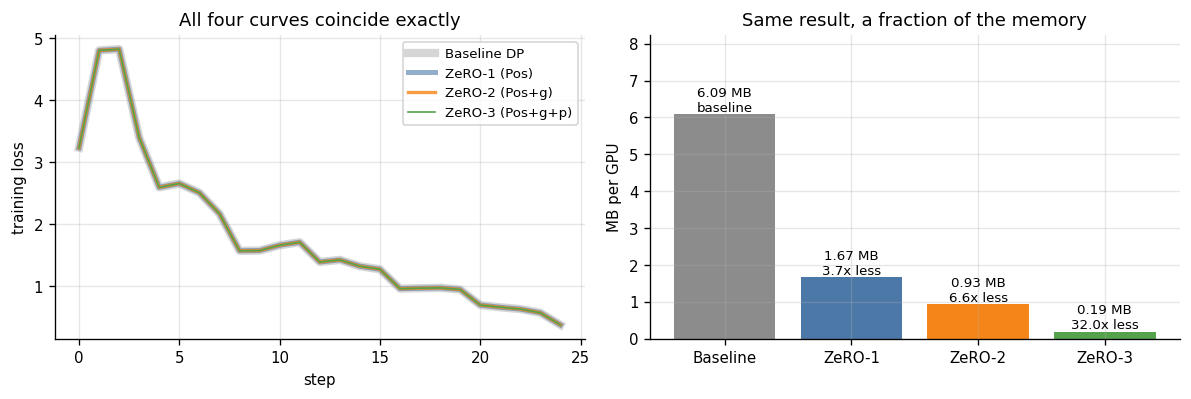

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for st in (0, 1, 2, 3):
    ax[0].plot(R[st]['losses'], color=COLORS[st], lw=[5, 3, 2, 1][st],
               alpha=[0.35, 0.6, 0.8, 1.0][st], label=STAGE_NAMES[st])
ax[0].set(xlabel='step', ylabel='training loss', title='All four curves coincide exactly')
ax[0].legend(fontsize=8)

memv = [sum(R[st]['mem'].values()) / MB for st in (0, 1, 2, 3)]
bars = ax[1].bar(range(4), memv, color=[COLORS[s] for s in (0, 1, 2, 3)])
for i, (b, v) in enumerate(zip(bars, memv)):
    tag = 'baseline' if i == 0 else f'{memv[0]/v:.1f}x less'
    ax[1].text(b.get_x() + b.get_width() / 2, v, f'{v:.2f} MB\n{tag}',
               ha='center', va='bottom', fontsize=8)
ax[1].set(xticks=range(4), ylim=(0, memv[0] * 1.35), ylabel='MB per GPU',
          title='Same result, a fraction of the memory')
ax[1].set_xticklabels(['Baseline', 'ZeRO-1', 'ZeRO-2', 'ZeRO-3'])
fig.tight_layout(); fig.savefig(FIGDIR / 'fig1_equivalence.png'); plt.show()

## 10. Memory: where the bytes actually went

The bars below are sums of `numpy` `.nbytes` over arrays that exist on virtual GPU 0. Notice how the
reduction arrives in tiers, and how each tier attacks a different block:

- **ZeRO-1** flattens the optimizer block (the tall one) but leaves params and grads replicated.
- **ZeRO-2** additionally flattens gradients — but `2Ψ` of fp16 parameters is now the floor.
- **ZeRO-3** removes the floor. Nothing is replicated, so everything scales as `1/N`.

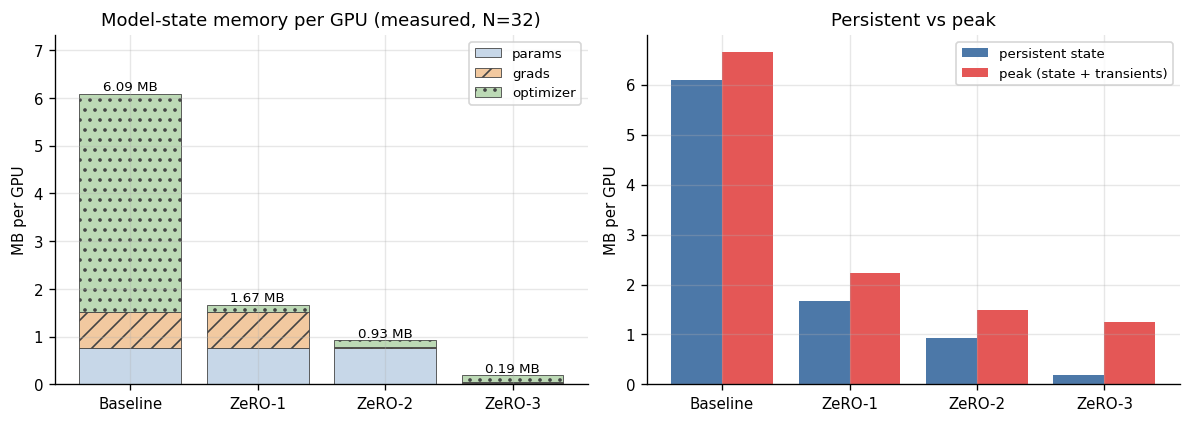

megabytes per GPU

            config    params     grads     optim     total      peak   vs base
       Baseline DP     0.762     0.762     4.571     6.094     6.658     1.00x
      ZeRO-1 (Pos)     0.762     0.762     0.143     1.666     2.230     3.66x
    ZeRO-2 (Pos+g)     0.762     0.024     0.143     0.928     1.493     6.56x
  ZeRO-3 (Pos+g+p)     0.024     0.024     0.143     0.190     1.256    32.00x


In [11]:
keys  = ['params', 'grads', 'optimizer']
hatch = {'params': '', 'grads': '//', 'optimizer': '..'}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))

bottom = np.zeros(4)
for k in keys:
    vals = np.array([R[st]['mem'][k] / MB for st in (0, 1, 2, 3)])
    ax[0].bar(range(4), vals, bottom=bottom, label=k, hatch=hatch[k],
              color=['#c7d7e8', '#f2c9a0', '#bcd9b5'][keys.index(k)], edgecolor='#444', lw=0.5)
    bottom += vals
for i, v in enumerate(bottom):
    ax[0].text(i, v, f'{v:.2f} MB', ha='center', va='bottom', fontsize=8)
ax[0].set(xticks=range(4), ylabel='MB per GPU', ylim=(0, bottom[0] * 1.2),
          title=f'Model-state memory per GPU (measured, N={N_GPUS})')
ax[0].set_xticklabels(['Baseline', 'ZeRO-1', 'ZeRO-2', 'ZeRO-3'])
ax[0].legend(fontsize=8)

pers = np.array([sum(R[st]['mem'].values()) / MB for st in (0, 1, 2, 3)])
pk   = np.array([R[st]['peak'] / MB for st in (0, 1, 2, 3)])
x = np.arange(4)
ax[1].bar(x - 0.2, pers, 0.4, label='persistent state', color='#4c78a8')
ax[1].bar(x + 0.2, pk, 0.4, label='peak (state + transients)', color='#e45756')
ax[1].set(xticks=x, ylabel='MB per GPU', title='Persistent vs peak')
ax[1].set_xticklabels(['Baseline', 'ZeRO-1', 'ZeRO-2', 'ZeRO-3'])
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGDIR / 'fig2_memory.png'); plt.show()

print('megabytes per GPU\n')
print(f"{'config':>18} {'params':>9} {'grads':>9} {'optim':>9} {'total':>9} {'peak':>9} {'vs base':>9}")
for st in (0, 1, 2, 3):
    m = R[st]['mem']; tot = sum(m.values())
    print(f"{STAGE_NAMES[st]:>18} {m['params']/MB:9.3f} {m['grads']/MB:9.3f} "
          f"{m['optimizer']/MB:9.3f} {tot/MB:9.3f} {R[st]['peak']/MB:9.3f} "
          f"{sum(R[0]['mem'].values())/tot:8.2f}x")

### Measurement vs theory

The closed-form column is the ZeRO paper's accounting. It is asserted against the measured bytes, not
merely printed next to them — which is what licenses using the formula for the extrapolation in
section 13, where actually allocating the tensors is not an option.

In [12]:
def model_state_bytes(psi, n, stage, K=12):
    """ZeRO paper accounting, in bytes, for mixed-precision Adam."""
    return {0: psi * 16.0,
            1: psi * 4.0 + psi * K / n,
            2: psi * 2.0 + psi * (2 + K) / n,
            3: psi * 16.0 / n}[stage]

print(f"{'config':>18} {'measured B':>14} {'formula B':>14}   match")
for st in (0, 1, 2, 3):
    meas = sum(R[st]['mem'].values())
    theo = model_state_bytes(PSI_PAD, N_GPUS, st)
    assert meas == theo, f'stage {st}: measured {meas} != formula {theo}'
    print(f'{STAGE_NAMES[st]:>18} {meas:>14,} {int(theo):>14,}   ok')
print('\nPASS: measured allocations match the 16psi / 4psi+12psi/N / 2psi+14psi/N / 16psi/N accounting.')

            config     measured B      formula B   match
       Baseline DP      6,390,272      6,390,272   ok
      ZeRO-1 (Pos)      1,747,340      1,747,340   ok
    ZeRO-2 (Pos+g)        973,518        973,518   ok
  ZeRO-3 (Pos+g+p)        199,696        199,696   ok

PASS: measured allocations match the 16psi / 4psi+12psi/N / 2psi+14psi/N / 16psi/N accounting.


### The transient that ZeRO-3 cannot shard

Persistent memory for ZeRO-3 is `16Ψ/N`, but its *peak* is visibly higher. The gap is the all-gather
buffer: to multiply by layer `i`, a rank must briefly hold **all** of layer `i`, not `1/N` of it. So
the real floor is

```
peak ≈ 16Ψ/N  +  (largest layer)  +  (its gradient bucket)  +  activations
```

At this toy scale with `N=32` the transient *dominates* — the biggest layer is 66% of the model, and
one layer of a 3-layer net is not small compared to `1/32` of it. That is not an artifact of the
simulation; it is the reason production ZeRO-3 prefetches, buckets sub-layer, and is paired with
activation checkpointing. It is also why ZeRO-3's advantage grows with depth: at 80 layers, one
gathered layer is 1.25% of the model, not 66%.

In [13]:
big = max(hi - lo for lo, hi in BUCKET)
print(f'largest layer bucket : {big:,} params = {big/PSI:.1%} of the model = {big*2/MB:.3f} MB in fp16')
print(f'ZeRO-3 persistent    : {sum(R[3]["mem"].values())/MB:.3f} MB')
print(f'ZeRO-3 peak          : {R[3]["peak"]/MB:.3f} MB')
print(f'  -> transient is {R[3]["peak"]/sum(R[3]["mem"].values()):.1f}x the persistent state here.')
print(f'\nactivations/GPU      : {GLOBAL_BATCH//N_GPUS * sum(o for _, o in LAYERS) * 2 / MB:.3f} MB'
      f'  (identical in all four configs -- ZeRO shards model state, not activations)')

largest layer bucket : 262,656 params = 65.8% of the model = 0.501 MB in fp16
ZeRO-3 persistent    : 0.190 MB
ZeRO-3 peak          : 1.256 MB
  -> transient is 6.6x the persistent state here.

activations/GPU      : 0.063 MB  (identical in all four configs -- ZeRO shards model state, not activations)


## 11. Communication: what ZeRO-3 actually costs

Memory is not free. The table below is the bill.

| config | collectives per step | volume |
|---|---|---|
| Baseline DP | all-reduce gradients | `2Ψ` |
| ZeRO-1 | reduce-scatter gradients + all-gather params | `Ψ + Ψ = 2Ψ` |
| ZeRO-2 | reduce-scatter per layer + all-gather params | `Ψ + Ψ = 2Ψ` |
| ZeRO-3 | all-gather (fwd) + all-gather (bwd) + reduce-scatter | `Ψ + Ψ + Ψ = 3Ψ` |

**ZeRO-1 and ZeRO-2 are free.** An all-reduce *is* a reduce-scatter followed by an all-gather; ZeRO
just does the optimizer step in between the halves instead of after both. Same bytes, less memory.

ZeRO-3 is the only stage that pays: **+50% traffic for 32x less memory.** In a real cluster most of
that gather is overlapped with compute by prefetching the next layer while the current one runs.

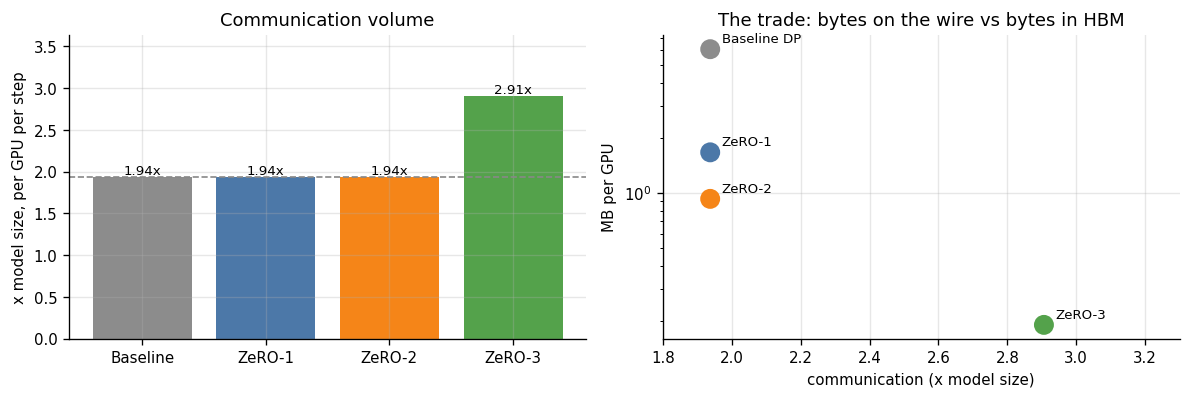

       Baseline DP   1.476 MB/step  (1.94x)   collectives/step: {'all_reduce': 1}
      ZeRO-1 (Pos)   1.476 MB/step  (1.94x)   collectives/step: {'reduce_scatter': 1, 'all_gather': 1}
    ZeRO-2 (Pos+g)   1.476 MB/step  (1.94x)   collectives/step: {'reduce_scatter': 3, 'all_gather': 1}
  ZeRO-3 (Pos+g+p)   2.214 MB/step  (2.91x)   collectives/step: {'all_gather': 6, 'reduce_scatter': 3}


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cv = [R[st]['comm'] / (PSI * WIRE) for st in (0, 1, 2, 3)]
b  = ax[0].bar(range(4), cv, color=[COLORS[s] for s in (0, 1, 2, 3)])
for bb, v in zip(b, cv):
    ax[0].text(bb.get_x() + bb.get_width() / 2, v, f'{v:.2f}x', ha='center', va='bottom', fontsize=8)
ax[0].axhline(cv[0], ls='--', lw=1, color='#888')
ax[0].set(xticks=range(4), ylabel='x model size, per GPU per step', ylim=(0, max(cv) * 1.25),
          title='Communication volume')
ax[0].set_xticklabels(['Baseline', 'ZeRO-1', 'ZeRO-2', 'ZeRO-3'])

ax[1].scatter(cv, [sum(R[st]['mem'].values()) / MB for st in (0, 1, 2, 3)],
              s=120, c=[COLORS[s] for s in (0, 1, 2, 3)], zorder=3)
for st in (0, 1, 2, 3):
    ax[1].annotate(STAGE_NAMES[st].split(' (')[0], (cv[st], sum(R[st]['mem'].values()) / MB),
                   textcoords='offset points', xytext=(7, 4), fontsize=8)
ax[1].set(xlabel='communication (x model size)', ylabel='MB per GPU', yscale='log',
          xlim=(1.8, 3.3), title='The trade: bytes on the wire vs bytes in HBM')
fig.tight_layout(); fig.savefig(FIGDIR / 'fig3_comm.png'); plt.show()

for st in (0, 1, 2, 3):
    print(f"{STAGE_NAMES[st]:>18}  {R[st]['comm']/MB:6.3f} MB/step  ({R[st]['comm']/(PSI*WIRE):4.2f}x)"
          f"   collectives/step: {R[st]['ops']}")

## 12. Computation: the model's arithmetic does not move; the optimizer step shrinks by N

ZeRO is a *memory* optimisation. It does not repartition the forward/backward — every rank still runs
the whole model over its own micro-batch, and the matmul FLOP count is identical across all four
configurations. Nothing is recomputed (that would be activation checkpointing, a different technique).
This is exactly what distinguishes ZeRO from tensor/model parallelism, which *does* split the
arithmetic and therefore needs high-bandwidth intra-node links to be viable.

The one piece of arithmetic that *does* change is the **optimizer step**. Under plain data parallelism
every rank runs Adam over all `Ψ` parameters — 32 GPUs computing the same update 32 times. From ZeRO-1
on, each rank updates only the `Ψ/N` shard whose optimizer state it owns, so optimizer work per GPU
falls by `N` and the cluster performs each parameter's update exactly once. Adam is elementwise
(`O(Ψ)`), small next to the `6·B·Ψ` of forward+backward, so this is a bonus rather than the headline —
but it is measured, not assumed.

In [15]:
fl = [R[st]['flops'] for st in (0, 1, 2, 3)]
assert len(set(fl)) == 1, 'FLOPs differ between stages -- ZeRO must not change the arithmetic'
mb_per_gpu = GLOBAL_BATCH // N_GPUS
print(f'FLOPs per GPU per step : {fl[0]/1e6:.2f} MFLOP  (identical in all four configs)')
print(f'aggregate across {N_GPUS} GPUs: {fl[0]*N_GPUS/1e9:.3f} GFLOP/step')
print(f'sanity check 6 * B * psi : {6*mb_per_gpu*PSI/1e6:.2f} MFLOP  '
      f'(ratio {fl[0]/(6*mb_per_gpu*PSI):.3f}; <1 because the bias terms carry no matmul)')
opt = [R[st]['opt'] for st in (0, 1, 2, 3)]
assert opt[0] == PSI_PAD and all(o == SHARD for o in opt[1:]), 'Adam must touch psi (baseline) or psi/N (ZeRO)'
print('\nAdam updates per GPU per step:')
for st in (0, 1, 2, 3):
    print(f"{STAGE_NAMES[st]:>18} {opt[st]:>9,.0f}   ({opt[0]/opt[st]:.0f}x less than baseline)")
print(f'cluster-wide: baseline does {opt[0]*N_GPUS:,.0f} updates/step ({N_GPUS} redundant copies), '
      f'ZeRO does {opt[1]*N_GPUS:,.0f} (each parameter once)')
print('\nPASS: matmul FLOPs unchanged; optimizer work per GPU drops by N.')

FLOPs per GPU per step : 76.48 MFLOP  (identical in all four configs)
aggregate across 32 GPUs: 2.447 GFLOP/step
sanity check 6 * B * psi : 76.68 MFLOP  (ratio 0.997; <1 because the bias terms carry no matmul)

Adam updates per GPU per step:
       Baseline DP   399,392   (1x less than baseline)
      ZeRO-1 (Pos)    12,481   (32x less than baseline)
    ZeRO-2 (Pos+g)    12,481   (32x less than baseline)
  ZeRO-3 (Pos+g+p)    12,481   (32x less than baseline)
cluster-wide: baseline does 12,780,544 updates/step (32 redundant copies), ZeRO does 399,392 (each parameter once)

PASS: matmul FLOPs unchanged; optimizer work per GPU drops by N.


## 13. Scaling: how each stage behaves as `N` grows

Sweeping the world size from 1 to 32 and re-measuring. Only the *allocation* is measured here (the
`VGPU`s are constructed and their bytes summed) — training them at every world size would take minutes
and teach nothing new, since section 10 already proved allocation matches the formula.

The shape of each curve is the point:

- **Baseline** is flat. Adding GPUs adds throughput and zero memory headroom.
- **ZeRO-1** flattens out at `4Ψ` — the replicated fp16 params and grads it never touches.
- **ZeRO-2** flattens out at `2Ψ`.
- **ZeRO-3** has no floor. It is the only stage where more GPUs means a bigger trainable model.

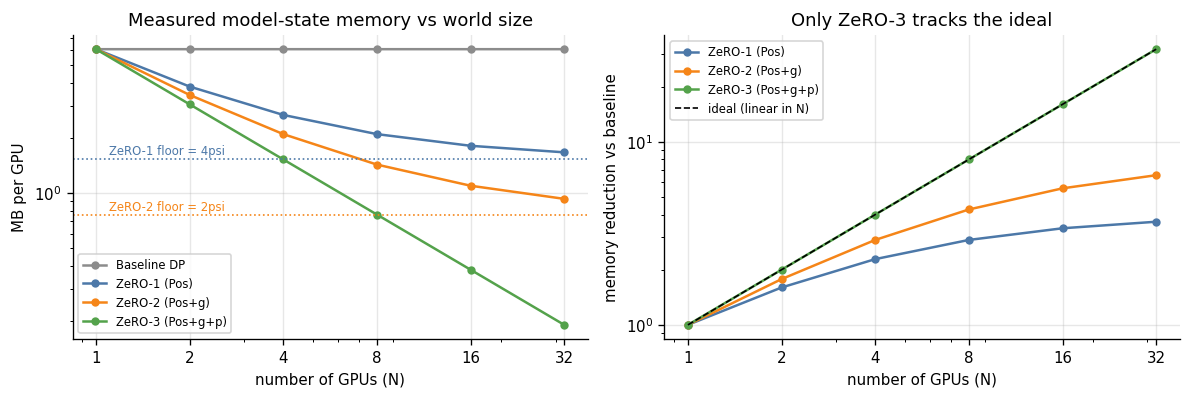

megabytes per GPU

   N     Baseline      ZeRO-1      ZeRO-2      ZeRO-3
   1        6.094       6.094       6.094       6.094
   2        6.094       3.809       3.428       3.047
   4        6.094       2.666       2.095       1.523
   8        6.094       2.095       1.428       0.762
  16        6.094       1.809       1.095       0.381
  32        6.094       1.666       0.928       0.190


In [16]:
def measure(n, stage):
    """Construct a rank at world size n and sum its real allocations."""
    shard = -(-PSI // n); pad = shard * n
    return sum(VGPU(0, stage, init_master(psi_pad=pad), shard=shard, psi_pad=pad)
               .state_bytes().values())

NS = [1, 2, 4, 8, 16, 32]
sweep = {st: [measure(n, st) / MB for n in NS] for st in (0, 1, 2, 3)}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for st in (0, 1, 2, 3):
    ax[0].plot(NS, sweep[st], 'o-', color=COLORS[st], label=STAGE_NAMES[st], ms=4)
ax[0].axhline(PSI * 4 / MB, ls=':', c='#4c78a8', lw=1)
ax[0].text(1.1, PSI * 4 / MB * 1.06, 'ZeRO-1 floor = 4psi', fontsize=7, color='#4c78a8')
ax[0].axhline(PSI * 2 / MB, ls=':', c='#f58518', lw=1)
ax[0].text(1.1, PSI * 2 / MB * 1.06, 'ZeRO-2 floor = 2psi', fontsize=7, color='#f58518')
ax[0].set(xscale='log', yscale='log', xticks=NS, xlabel='number of GPUs (N)',
          ylabel='MB per GPU', title='Measured model-state memory vs world size')
ax[0].set_xticklabels(NS); ax[0].legend(fontsize=7)

for st in (1, 2, 3):
    ax[1].plot(NS, [sweep[0][i] / sweep[st][i] for i in range(len(NS))], 'o-',
               color=COLORS[st], label=STAGE_NAMES[st], ms=4)
ax[1].plot(NS, NS, 'k--', lw=1, label='ideal (linear in N)')
ax[1].set(xscale='log', yscale='log', xticks=NS, xlabel='number of GPUs (N)',
          ylabel='memory reduction vs baseline', title='Only ZeRO-3 tracks the ideal')
ax[1].set_xticklabels(NS); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGDIR / 'fig4_scaling.png'); plt.show()

print('megabytes per GPU\n')
print(f"{'N':>4} " + ''.join(f'{STAGE_NAMES[s].split(chr(32))[0]:>12}' for s in (0, 1, 2, 3)))
for i, n in enumerate(NS):
    print(f'{n:>4} ' + ''.join(f'{sweep[s][i]:12.3f}' for s in (0, 1, 2, 3)))

## 14. What this means at real model sizes

The formula has now been checked against measured allocations at every world size above, so it can be
pushed to scales that will not fit in this notebook. All figures are **GB per GPU at `N=32`**, model
states only (activations extra), against an 80 GB H100.

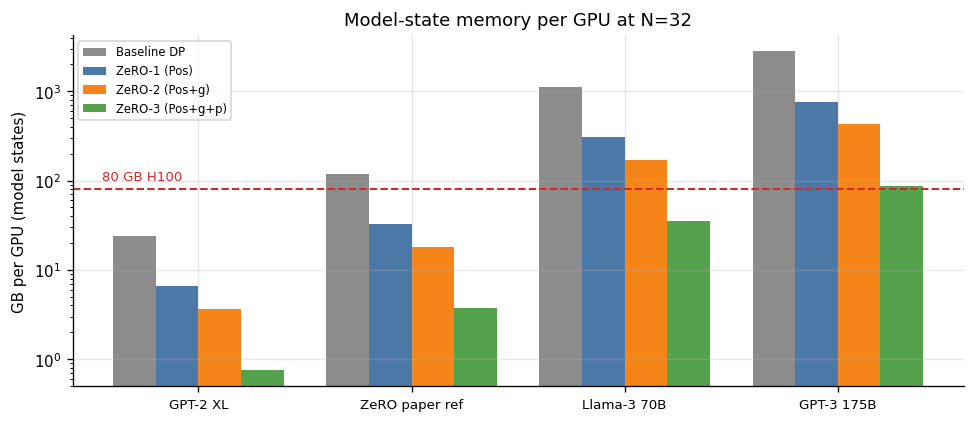

GB per GPU at N=32   (* = does not fit in 80 GB)

           model   params      Baseline       ZeRO-1       ZeRO-2       ZeRO-3
        GPT-2 XL     1.5B          24        6.562        3.656         0.75  
  ZeRO paper ref     7.5B         120*       32.81        18.28         3.75  
     Llama-3 70B      70B        1120*       306.2*       170.6*          35  
      GPT-3 175B     175B        2800*       765.6*       426.6*        87.5* 


In [17]:
GB = 1e9
MODELS = [('GPT-2 XL', 1.5e9), ('ZeRO paper ref', 7.5e9), ('Llama-3 70B', 70e9),
          ('GPT-3 175B', 175e9)]
LIMIT = 80.0

def hp(p):
    for unit, div in (('B', 1e9), ('M', 1e6), ('K', 1e3)):
        if p >= div:
            return f'{p/div:.3g}{unit}'
    return str(int(p))

fig, ax = plt.subplots(figsize=(8.2, 3.6))
w = 0.2
for k, st in enumerate((0, 1, 2, 3)):
    v = [model_state_bytes(p, N_GPUS, st) / GB for _, p in MODELS]
    ax.bar(np.arange(len(MODELS)) + (k - 1.5) * w, v, w, color=COLORS[st], label=STAGE_NAMES[st])
ax.axhline(LIMIT, ls='--', c='#d62728', lw=1.2)
ax.text(-0.45, LIMIT * 1.25, '80 GB H100', color='#d62728', fontsize=8)
ax.set(yscale='log', xticks=range(len(MODELS)), ylabel='GB per GPU (model states)',
       title=f'Model-state memory per GPU at N={N_GPUS}')
ax.set_xticklabels([m for m, _ in MODELS], fontsize=8)
ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGDIR / 'fig5_projection.png'); plt.show()

print(f'GB per GPU at N={N_GPUS}   (* = does not fit in {LIMIT:.0f} GB)\n')
print(f"{'model':>16} {'params':>8} " + ''.join(f'{STAGE_NAMES[s].split(chr(32))[0]:>13}' for s in (0,1,2,3)))
for name, p in MODELS:
    row = ''
    for st in (0, 1, 2, 3):
        g = model_state_bytes(p, N_GPUS, st) / GB
        row += f'{g:11.4g}{"*" if g > LIMIT else " "} '
    print(f'{name:>16} {hp(p):>8} {row}')

### Reading that table

- A **7.5B** model needs 120 GB/GPU under plain data parallelism — it does not fit on anything.
  ZeRO-1 alone (free, no extra communication) brings it to ~33 GB and it trains on 32 GPUs.
- A **70B** model is out of reach for every stage except ZeRO-3, which lands at 35 GB.
- **175B** does not fit at `N=32` even with ZeRO-3 (87.5 GB). The answer is more GPUs — `16Ψ/N` keeps
  falling — or ZeRO-Infinity's offload to CPU/NVMe. Nothing in this notebook is a free lunch; ZeRO-3
  converts a memory problem into a bandwidth problem, and at some point you must buy more of one.

## 15. Summary

Everything below was measured in this notebook, not quoted.

In [18]:
print(f"{'':>18} {'MB/GPU':>9} {'vs base':>9} {'peak MB':>9} {'comm x':>8} {'MFLOP':>8} {'Adam upd':>9} {'final loss':>11}")
for st in (0, 1, 2, 3):
    tot = sum(R[st]['mem'].values())
    print(f"{STAGE_NAMES[st]:>18} {tot/MB:9.3f} {sum(R[0]['mem'].values())/tot:8.2f}x "
          f"{R[st]['peak']/MB:9.3f} {R[st]['comm']/(PSI*WIRE):8.2f} {R[st]['flops']/1e6:8.1f} {R[st]['opt']:9,.0f} "
          f"{R[st]['losses'][-1]:11.6f}")
print(f'\nfigures written to {FIGDIR}/')

                      MB/GPU   vs base   peak MB   comm x    MFLOP  Adam upd  final loss
       Baseline DP     6.094     1.00x     6.658     1.94     76.5   399,392    0.371121
      ZeRO-1 (Pos)     1.666     3.66x     2.230     1.94     76.5    12,481    0.371121
    ZeRO-2 (Pos+g)     0.928     6.56x     1.493     1.94     76.5    12,481    0.371121
  ZeRO-3 (Pos+g+p)     0.190    32.00x     1.256     2.91     76.5    12,481    0.371121

figures written to figures/


### What the numbers say

1. **ZeRO-1 and ZeRO-2 are strictly free.** Same matmul FLOPs, same communication volume, same loss —
   3.7x and 6.6x less memory, and 32x less optimizer work per GPU. There is no reason not to turn them on.
2. **ZeRO-3 buys the remaining 32x for +50% communication.** It is the only stage whose memory keeps
   falling as the cluster grows, which is what makes >10B-parameter training possible at all.
3. **The model's compute never moved.** Identical matmul FLOPs everywhere; the only arithmetic that
   changes is the optimizer step, which stops being done 32 times over. ZeRO redistributes *state* —
   the property that lets it scale across ordinary inter-node networks, unlike tensor parallelism.
4. **Peak != persistent.** ZeRO-3's transient all-gather buffer dominated at this scale. Depth is what
   amortises it, which is why real deployments pair ZeRO-3 with prefetching and checkpointing.

### What this simulation leaves out

Honest limitations, so the numbers are not over-read:

- Ranks run **sequentially**; there is no wall-clock speedup to report and none is claimed. Bandwidth,
  latency and compute/communication overlap are not modelled — a real ZeRO-3 run hides much of that
  extra `Ψ` behind compute via prefetch.
- **Activation memory** is measured but not optimised; activation checkpointing and ZeRO-R are out of
  scope. On deep models activations often dominate, and ZeRO does not address them.
- No **CPU/NVMe offload** (ZeRO-Infinity), no gradient accumulation, no tensor or pipeline parallelism.
- The model is a 3-layer MLP, so one layer is a large fraction of it — which exaggerates ZeRO-3's
  transient peak relative to a realistic deep transformer.

### Reference

Rajbhandari, Rasley, Ruwase, He. *ZeRO: Memory Optimizations Toward Training Trillion Parameter
Models.* SC'20. [arXiv:1910.02054](https://arxiv.org/abs/1910.02054)